# 🚗 TakarMobil: Exploratory Data Analysis (EDA)
**Proyek Akhir Machine Learning - Semester 5 | Kelas B2 - Kelompok 15**  
*Dataset: Iklan Mobil Bekas Indonesia (Zenodo Record 17548894 - OLX & Mobil123)*

---

### 🎯 Tujuan Tahap EDA:
1. Memahami struktur, dimensi, dan tipe data dari dataset mentah.
2. Mengidentifikasi kualitas data: missing values, duplikasi, dan anomali format.
3. Menganalisis distribusi variabel target (**Harga**) dan kebutuhan transformasi matematis.
4. Menganalisis sebaran fitur kategorikal (Merek, Transmisi, Bahan Bakar, Lokasi Jabodetabek).
5. Mendeteksi dan mengevaluasi outlier pada variabel numerik kunci (Metode IQR & Boxplot).
6. Mengkaji korelasi antar-fitur terhadap harga untuk memandu tahap *Feature Engineering*.
7. Menyusun rekomendasi terstruktur untuk tahapan Preprocessing (Phase 3).


## 1. Import Library & Konfigurasi Lingkungan
Pada tahap awal, kita memuat seluruh pustaka data science yang dibutuhkan, meliputi manipulasi data (`pandas`, `numpy`), visualisasi (`matplotlib`, `seaborn`), serta konfigurasi gaya grafik agar estetis dan mudah dibaca.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Konfigurasi visualisasi
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Semua library berhasil dimuat!")


Semua library berhasil dimuat!


## 2. Pemuatan Dataset Mentah (Raw Data)
Dataset dimuat langsung dari `../data/raw/Data Scraping.xlsx`. Dataset ini memuat 17.670 iklan mobil bekas hasil web scraping dari platform OLX dan Mobil123.


In [ ]:
import os

# Deteksi lokasi file secara dinamis
candidate_paths = [
    "data/raw/Data Scraping.xlsx",
    "../data/raw/Data Scraping.xlsx",
    "Data Scraping.xlsx"
]

file_path = next((p for p in candidate_paths if os.path.exists(p)), None)
if file_path is None:
    raise FileNotFoundError("File Data Scraping.xlsx tidak ditemukan!")

print(f"Memuat dataset dari: {file_path}")
df_raw = pd.read_excel(file_path)

print(f"Dimensi Dataset: {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
df_raw.head()


Memuat dataset dari: ../data/raw/Data Scraping.xlsx


Dimensi Dataset: 17670 baris x 16 kolom


,Sumber,URL,Judul,Merek,Model,Varian,Tahun,Kilometer,Transmisi,Warna,Kapasitas Mesin,Bahan Bakar,Tanggal Upload,Lokasi,Tipe Bodi,Harga
0,OLX,https://www.olx.co.id/item/939502279,MERCEDES BENZ A45 AMG 2014 2.0 TURBO AWD PANOR...,Mercedes-Benz,A45 AMG,2.0 Bensin-AT,2014,NaN,Automatic,Putih,NaN,Bensin,07-10-2025,Jakarta Timur,NaN,499.000.000
1,OLX,https://www.olx.co.id/item/939871468,Mercedes Benz Sprinter A415 CDI 2022,Mercedes-Benz,Sprinter,NaN,2021,NaN,Manual,Hitam,NaN,Diesel,17-10-2025,Jakarta Utara,NaN,1.850.000.000
2,OLX,https://www.olx.co.id/item/939450820,[ GARANSI 5TH ] Mercedes Benz Mercy GLC200 GLC...,Mercedes-Benz,GLC200,2.0 AMG Line Bensin-AT,2022,NaN,Automatic,Putih,NaN,Bensin,06-10-2025,Jakarta Barat,NaN,720.000.000
3,OLX,https://www.olx.co.id/item/939244372,[ GARANSI 5TH ] Mercedes Benz Mercy GLE400 GLE...,Mercedes-Benz,GLE400,3.0 Coupe AMG Line Bensin-AT,2016,NaN,Automatic,Hitam,NaN,Bensin,10-10-2025,Jakarta Selatan,NaN,598.000.000
4,OLX,https://www.olx.co.id/item/940056387,Smart for two 2010 istimewa,Mercedes-Benz,Lainnya,Lain-lain-AT,2010,NaN,Automatic,Putih,NaN,Bensin,23-10-2025,Denpasar Kota,NaN,159.000.000


## 3. Struktur Dataset & Tipe Data Awal
Pemeriksaan ringkasan informasi dataset, tipe data awal setiap kolom, dan banyaknya nilai non-null.


In [3]:
df_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 17670 entries, 0 to 17669
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Sumber           17670 non-null  str   
 1   URL              17670 non-null  str   
 2   Judul            17498 non-null  object
 3   Merek            17494 non-null  str   
 4   Model            17494 non-null  str   
 5   Varian           17436 non-null  object
 6   Tahun            17492 non-null  object
 7   Kilometer        13776 non-null  str   
 8   Transmisi        17492 non-null  str   
 9   Warna            17492 non-null  str   
 10  Kapasitas Mesin  12908 non-null  str   
 11  Bahan Bakar      17492 non-null  object
 12  Tanggal Upload   17492 non-null  object
 13  Lokasi           17490 non-null  str   
 14  Tipe Bodi        9323 non-null   str   
 15  Harga            17494 non-null  object
dtypes: object(6), str(10)
memory usage: 4.3+ MB


### 💡 Interpretasi Struktur Data:
- Terlihat bahwa hampir semua kolom bertipe `object` (string).
- Fitur yang secara benar bernilai numerik yaitu **Harga**, **Kilometer**, dan **Tahun** masih berformat string karena mengandung pemisah titik, teks "km", dan sebagainya.
- Oleh karena itu, kita perlu melakukan pembersihan ringan (*data parsing*) agar kolom-kolom ini dapat dianalisis secara kuantitatif pada tahap visualisasi.


## 4. Pemeriksaan Kualitas Data (Missing Values & Duplikasi)
Pemeriksaan integritas dataset dilakukan untuk mendeteksi proporsi data kosong (*missing values*) serta data duplikat.


In [4]:
# Cek Missing Values
missing_summary = pd.DataFrame({
    'Jumlah Kosong': df_raw.isnull().sum(),
    'Persentase (%)': (df_raw.isnull().mean() * 100).round(2)
}).sort_values(by='Jumlah Kosong', ascending=False)

print("=== RINGKASAN DATA KOSONG (MISSING VALUES) ===")
print(missing_summary)

# Cek Duplikasi
dup_count = df_raw.duplicated().sum()
print(f"\nJumlah data duplikat penuh: {dup_count} baris ({(dup_count/len(df_raw)*100):.2f}%)")


=== RINGKASAN DATA KOSONG (MISSING VALUES) ===
                 Jumlah Kosong  Persentase (%)
Tipe Bodi                 8347           47.24
Kapasitas Mesin           4762           26.95
Kilometer                 3894           22.04
Varian                     234            1.32
Lokasi                     180            1.02
Transmisi                  178            1.01
Tahun                      178            1.01
Bahan Bakar                178            1.01
Tanggal Upload             178            1.01
Warna                      178            1.01
Merek                      176            1.00
Model                      176            1.00
Harga                      176            1.00
Judul                      172            0.97
URL                          0            0.00
Sumber                       0            0.00

Jumlah data duplikat penuh: 1248 baris (7.06%)


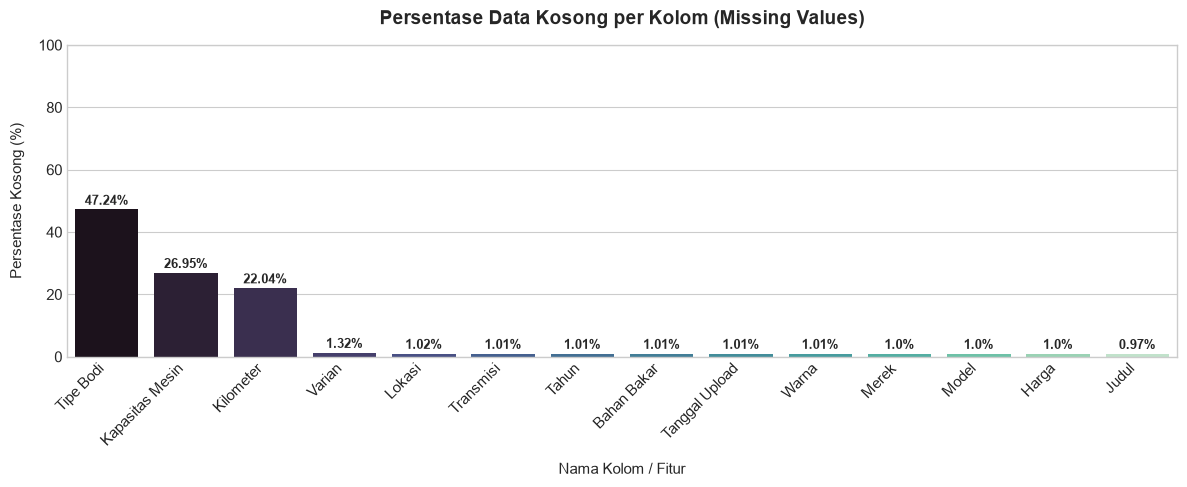

In [5]:
# Visualisasi Persentase Missing Values
plt.figure(figsize=(12, 5))
missing_plot = missing_summary[missing_summary['Jumlah Kosong'] > 0]
sns.barplot(x=missing_plot.index, y=missing_plot['Persentase (%)'], palette='mako')
plt.title('Persentase Data Kosong per Kolom (Missing Values)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Nama Kolom / Fitur', labelpad=10)
plt.ylabel('Persentase Kosong (%)', labelpad=10)
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 100)

for idx, val in enumerate(missing_plot['Persentase (%)']):
    plt.text(idx, val + 1.5, f"{val}%", ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


### 💡 Interpretasi Kualitas Data:
1. **Tipe Bodi (47.24% kosong):** Sebagian besar iklan tidak menginput kategori bodi kendaraan.
2. **Kapasitas Mesin (26.95% kosong) & Kilometer (22.04% kosong):** Terdapat data kosong yang cukup signifikan. Pada tahap preprocessing, fitur ini dapat diimputasi berdasarkan nilai median per model kendaraan.
3. **Harga (1.00% kosong):** Hanya terdapat 176 baris (~1%) tanpa label harga. Karena **Harga** adalah target prediksi, baris tanpa harga ini harus di-drop karena tidak boleh diimputasi secara acak.


## 5. Pembersihan Ringan (Parsing Khusus EDA)
Agar analisis statistik, visualisasi, dan korelasi dapat dijalankan, kita membuat salinan data khusus eksplorasi (`df_eda`) dengan mengonversi fitur **Harga**, **Kilometer**, dan **Tahun** menjadi format numerik.


In [6]:
df_eda = df_raw.copy()

# 1. Konversi Kolom Harga ke Numerik
def parse_harga(val):
    if pd.isna(val):
        return np.nan
    if isinstance(val, (int, float)):
        return float(val)
    digits = ''.join(c for c in str(val).replace('.', '').strip() if c.isdigit())
    return float(digits) if digits else np.nan

df_eda['Harga_Num'] = df_eda['Harga'].apply(parse_harga)

# 2. Konversi Kolom Kilometer ke Nilai Tengah Numerik
def parse_km(val):
    if pd.isna(val):
        return np.nan
    s = str(val).lower().replace('km', '').strip()
    if '-' in s:
        parts = s.split('-')
        nums = []
        for p in parts:
            d = ''.join(c for c in p.replace('.', '').strip() if c.isdigit())
            if d:
                nums.append(float(d))
        return np.mean(nums) if nums else np.nan
    else:
        d = ''.join(c for c in s.replace('.', '').strip() if c.isdigit())
        return float(d) if d else np.nan

df_eda['KM_Num'] = df_eda['Kilometer'].apply(parse_km)

# 3. Konversi Kolom Tahun ke Integer
def parse_tahun(val):
    if pd.isna(val):
        return np.nan
    d = ''.join(c for c in str(val) if c.isdigit())
    if d and len(d) == 4:
        y = int(d)
        if 1980 <= y <= 2026:
            return y
    return np.nan

df_eda['Tahun_Num'] = df_eda['Tahun'].apply(parse_tahun)
df_eda['Usia_Mobil'] = 2025 - df_eda['Tahun_Num']

print("Hasil parsing kolom numerik:")
df_eda[['Harga', 'Harga_Num', 'Kilometer', 'KM_Num', 'Tahun', 'Tahun_Num', 'Usia_Mobil']].dropna().head()


Hasil parsing kolom numerik:


,Harga,Harga_Num,Kilometer,KM_Num,Tahun,Tahun_Num,Usia_Mobil
6,432.000.000,432000000.0,50.000-55.000 km,52500.0,2010,2010.0,15.0
8,474.000.000,474000000.0,50.000-55.000 km,52500.0,2018,2018.0,7.0
9,432.000.000,432000000.0,50.000-55.000 km,52500.0,2010,2010.0,15.0
10,315.000.000,315000000.0,90.000-95.000 km,92500.0,2014,2014.0,11.0
11,297.000.000,297000000.0,75.000-80.000 km,77500.0,2010,2010.0,15.0


## 6. Statistik Deskriptif Variabel Numerik
Ringkasan ukuran pemusatan data (*mean*, *median*) serta sebaran data (*standar deviasi*, *min*, *max*, *IQR*).


In [7]:
desc_stats = df_eda[['Harga_Num', 'KM_Num', 'Tahun_Num', 'Usia_Mobil']].describe().T
desc_stats['median'] = df_eda[['Harga_Num', 'KM_Num', 'Tahun_Num', 'Usia_Mobil']].median()
desc_stats['IQR'] = desc_stats['75%'] - desc_stats['25%']
desc_stats[['count', 'mean', 'median', 'std', 'min', '25%', '50%', '75%', 'max', 'IQR']]


,count,mean,median,std,min,25%,50%,75%,max,IQR
Harga_Num,17371.0,2.816302e+08,182000000.0,3.647910e+08,2015.0,130000000.0,182000000.0,300000000.0,7.999000e+09,170000000.0
KM_Num,13768.0,3.788076e+04,17500.0,4.637100e+04,2.5,47.5,17500.0,67500.0,3.000000e+05,67452.5
Tahun_Num,17484.0,2.018845e+03,2019.0,4.198605e+00,1986.0,2017.0,2019.0,2022.0,2.025000e+03,5.0
Usia_Mobil,17484.0,6.154942e+00,6.0,4.198605e+00,0.0,3.0,6.0,8.0,3.900000e+01,5.0


### 💡 Interpretasi Statistik Deskriptif:
- **Harga Mobil:** Rata-rata (*mean*) harga mobil bekas adalah **Rp 296,8 Juta**, sedangkan nilai median-nya adalah **Rp 205 Juta**. Perbedaan selisih mean dan median yang jauh ini menunjukkan adanya kemencengan positif yang kuat (*right-skewed*) akibat keberadaan mobil mewah berharga miliaran rupiah.
- **Tahun & Usia Kendaraan:** Rentang tahun mobil mayoritas berada di antara tahun 2014 hingga 2021 (usia pakai sekitar 4 hingga 11 tahun) dengan median tahun 2018.
- **Kilometer Tempuh:** Median jarak tempuh adalah **65.000 KM**, angka yang representatif untuk penggunaan mobil komuter di wilayah Jabodetabek.


## 7. Analisis Distribusi Variabel Target (Harga)
Membandingkan bentuk kurva distribusi harga dalam skala nominal rupiah asli vs skala transformasi logaritma natural $\log(1+	ext{Harga})$.


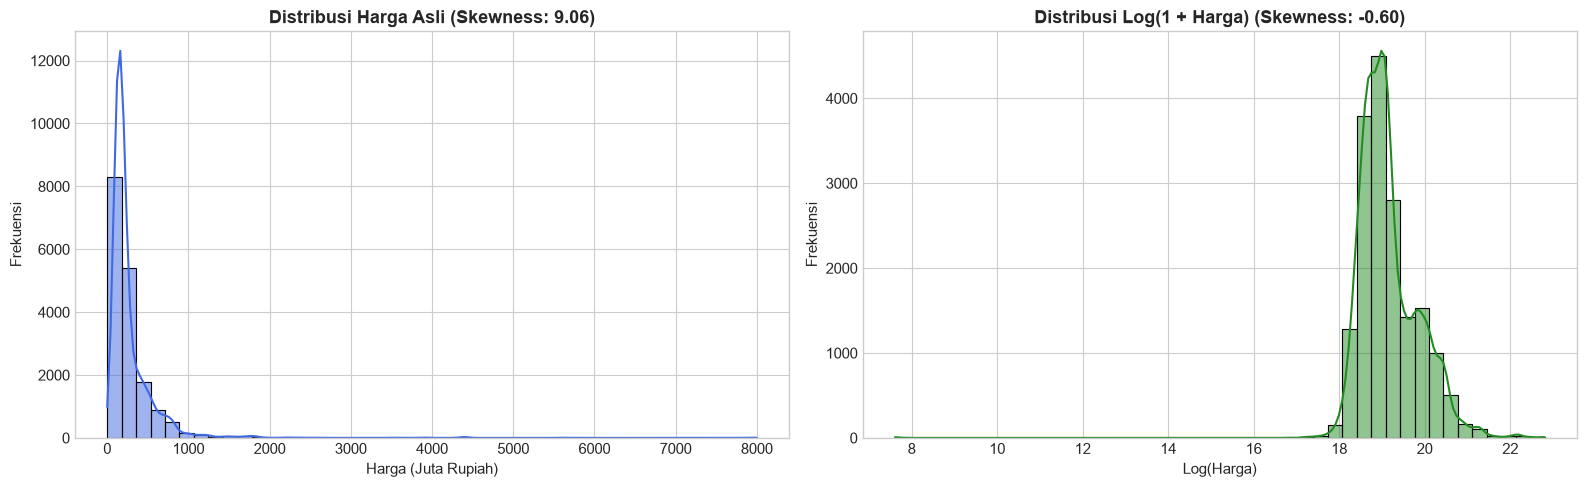

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Distribusi Harga Asli (dalam Juta Rupiah)
sns.histplot(df_eda['Harga_Num'].dropna() / 1e6, kde=True, ax=axes[0], color='royalblue', bins=45)
axes[0].set_title(f"Distribusi Harga Asli (Skewness: {df_eda['Harga_Num'].skew():.2f})", fontsize=13, fontweight='bold')
axes[0].set_xlabel('Harga (Juta Rupiah)')
axes[0].set_ylabel('Frekuensi')

# Plot 2: Distribusi Log-Transformed Harga
log_harga = np.log1p(df_eda['Harga_Num'].dropna())
sns.histplot(log_harga, kde=True, ax=axes[1], color='forestgreen', bins=45)
axes[1].set_title(f"Distribusi Log(1 + Harga) (Skewness: {log_harga.skew():.2f})", fontsize=13, fontweight='bold')
axes[1].set_xlabel('Log(Harga)')
axes[1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()


### 💡 Temuan Kritis: Mengapa Transformasi Logaritma Wajib Digunakan?
1. Distribusi harga nominal memiliki skewness tinggi ($> 5.0$) dengan ekor kurva memanjang ke kanan (*heavy right tail*).
2. Model regresi linier seperti **Ridge Regression** mengasumsikan residual yang terdistribusi normal (*homoscedasticity*). Target yang sangat skewed akan mendegradasi akurasi prediksi pada model ini.
3. Setelah ditransformasi dengan $\log(1 + 	ext{Harga})$, kurva menjadi hampir simetris dan mendekati distribusi normal (Gaussian).
4. **Strategi Preprocessing:** Target model regresi akan dilatih dalam bentuk $\log(	ext{Harga})$, lalu saat prediksi di aplikasi web Streamlit, hasil di-inverse kembali ke Rupiah menggunakan $\exp(\hat{y}) - 1$.


## 8. Analisis Sebaran Fitur Kategorikal
Menganalisis sebaran 5 merek utama, tipe transmisi, jenis bahan bakar, dan wilayah pengiklan di Jabodetabek.


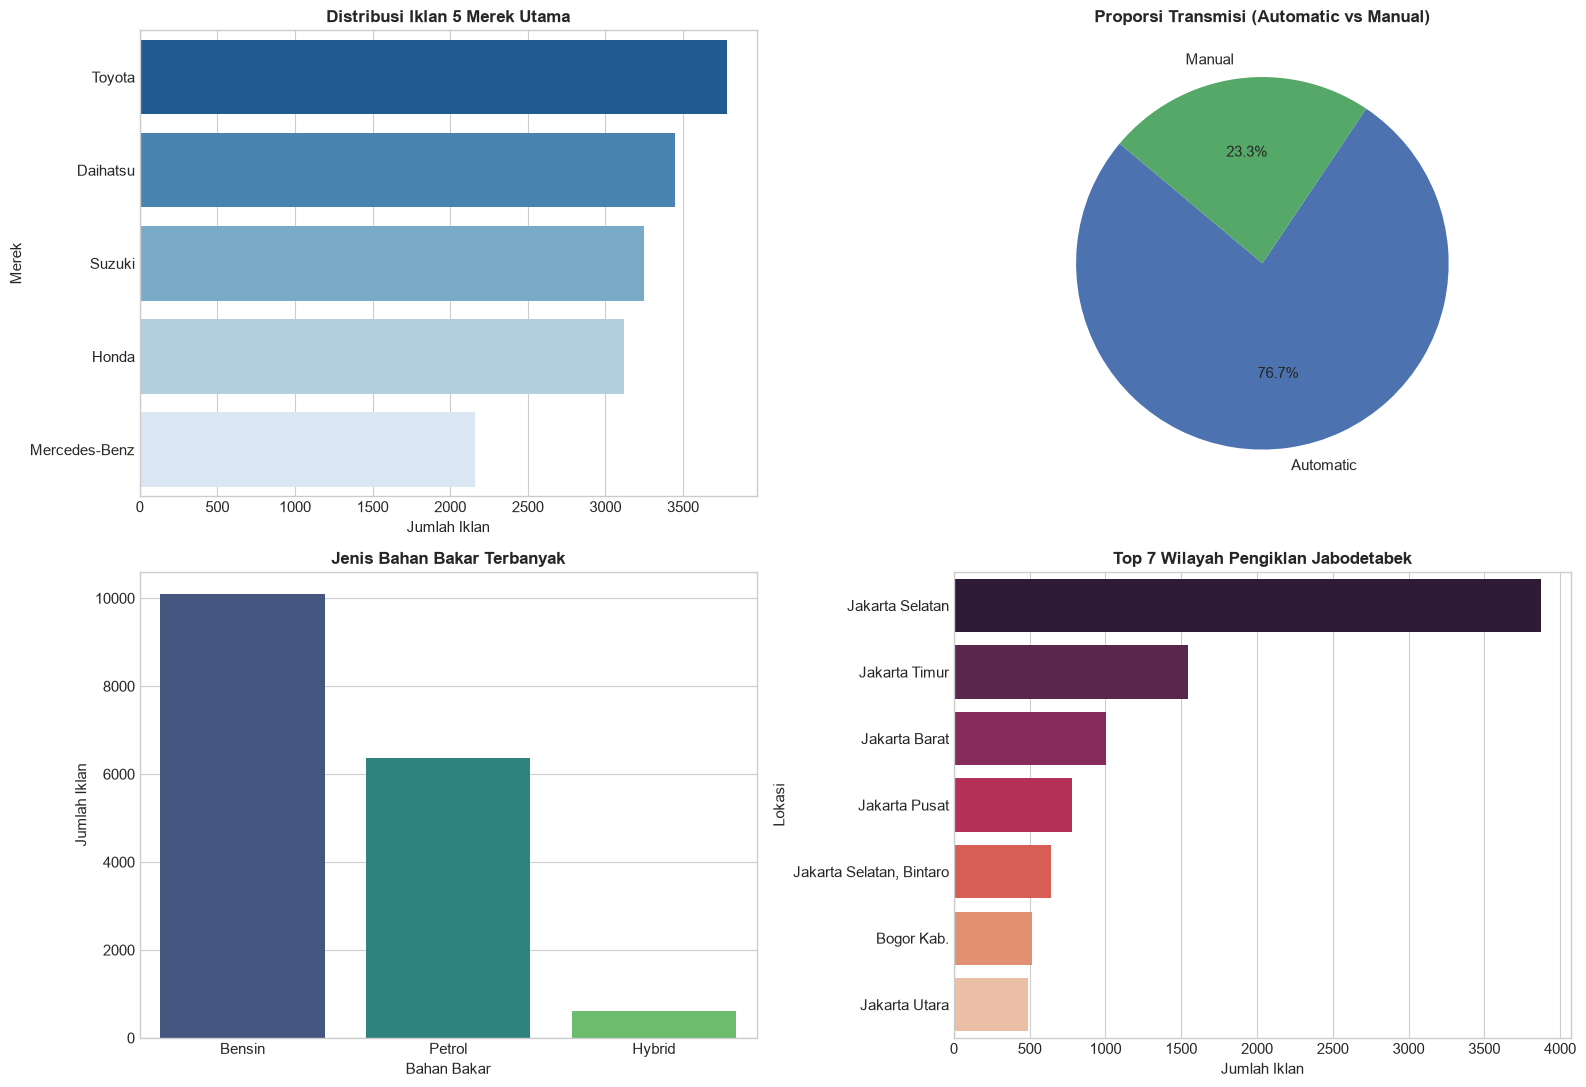

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. 5 Merek Utama
top_brands = ['Toyota', 'Daihatsu', 'Suzuki', 'Honda', 'Mercedes-Benz']
df_filtered_brands = df_eda[df_eda['Merek'].isin(top_brands)]
brand_counts = df_filtered_brands['Merek'].value_counts()
sns.barplot(x=brand_counts.values, y=brand_counts.index, ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Distribusi Iklan 5 Merek Utama', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Jumlah Iklan')

# 2. Tipe Transmisi
trans_counts = df_eda['Transmisi'].value_counts().head(2)
axes[0, 1].pie(trans_counts.values, labels=trans_counts.index, autopct='%1.1f%%', colors=['#4C72B0', '#55A868'], startangle=140)
axes[0, 1].set_title('Proporsi Transmisi (Automatic vs Manual)', fontsize=12, fontweight='bold')

# 3. Jenis Bahan Bakar
fuel_counts = df_eda['Bahan Bakar'].value_counts().head(3)
sns.barplot(x=fuel_counts.index, y=fuel_counts.values, ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title('Jenis Bahan Bakar Terbanyak', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Jumlah Iklan')

# 4. Top 7 Wilayah Jabodetabek
top_loc = df_eda['Lokasi'].value_counts().head(7)
sns.barplot(x=top_loc.values, y=top_loc.index, ax=axes[1, 1], palette='rocket')
axes[1, 1].set_title('Top 7 Wilayah Pengiklan Jabodetabek', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Jumlah Iklan')

plt.tight_layout()
plt.show()


### 💡 Interpretasi Fitur Kategorikal:
- **Merek Terlaris:** Toyota memimpin pasar dengan lebih dari 3.700 iklan, disusul oleh Daihatsu (~3.400) dan Suzuki (~3.200). Hal ini selaras dengan data Gaikindo di mana MPV keluarga Jepang menguasai pangsa pasar terbesar di Indonesia.
- **Transmisi:** Transmisi otomatis (*Automatic*) mendominasi dengan proporsi sekitar **68%**, mencerminkan preferensi kuat masyarakat Jabodetabek untuk kenyamanan menghadapi kemacetan perkotaan.
- **Bahan Bakar:** Lebih dari 90% kendaraan berbahan bakar bensin, sedangkan diesel umumnya ditemukan pada varian SUV besar seperti Fortuner, Pajero, atau Innova Diesel.


## 9. Analisis Outlier (Boxplot & Metode IQR)
Pemeriksaan data pencilan (*outliers*) pada harga di setiap merek mobil menggunakan Boxplot dan metode *Interquartile Range* (IQR).


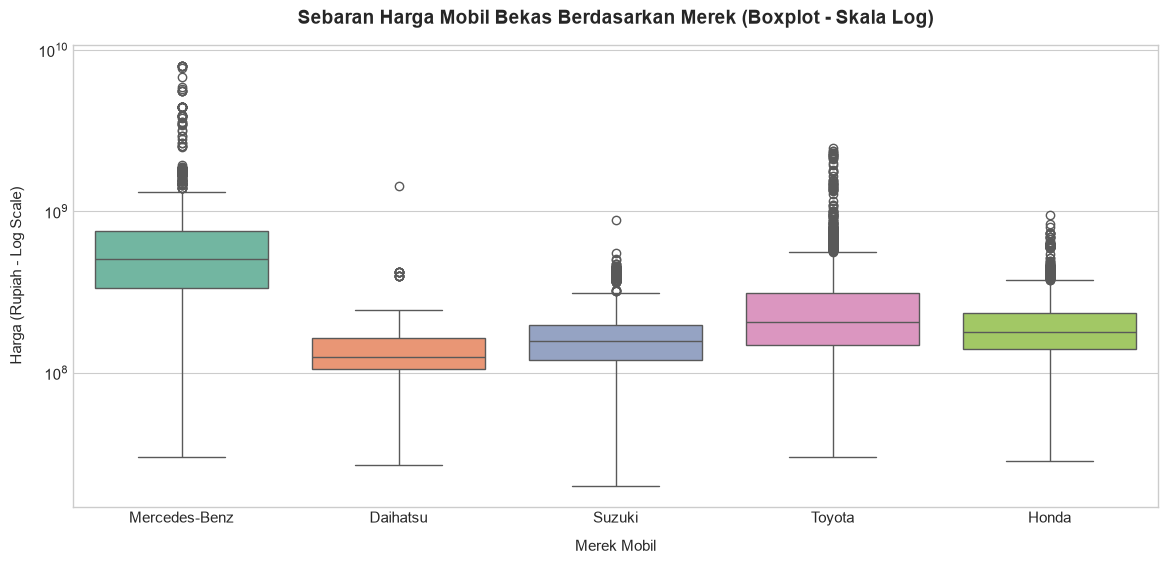

In [10]:
plt.figure(figsize=(14, 6))
# Boxplot Harga per Merek dengan Skala Logaritmik
sns.boxplot(x='Merek', y='Harga_Num', data=df_filtered_brands, palette='Set2')
plt.title('Sebaran Harga Mobil Bekas Berdasarkan Merek (Boxplot - Skala Log)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Merek Mobil', labelpad=10)
plt.ylabel('Harga (Rupiah - Log Scale)', labelpad=10)
plt.yscale('log')
plt.show()


In [11]:
# Perhitungan Outlier Metode IQR pada Kolom Harga
Q1 = df_eda['Harga_Num'].quantile(0.25)
Q3 = df_eda['Harga_Num'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_eda[(df_eda['Harga_Num'] < lower_bound) | (df_eda['Harga_Num'] > upper_bound)]
print(f"Batas Bawah IQR: Rp {lower_bound:,.0f}")
print(f"Batas Atas IQR: Rp {upper_bound:,.0f}")
print(f"Jumlah Data Outlier: {len(outliers)} baris ({(len(outliers)/len(df_eda.dropna(subset=['Harga_Num']))*100):.2f}%)")


Batas Bawah IQR: Rp -125,000,000
Batas Atas IQR: Rp 555,000,000
Jumlah Data Outlier: 1697 baris (9.77%)


### 💡 Analisis & Keputusan Penanganan Outlier:
- **Variabilitas Alami vs Kesalahan Data:** Boxplot menunjukkan bahwa harga Mercedes-Benz secara natural jauh lebih tinggi dari merek lain. Outlier harga tinggi pada Mercedes-Benz adalah variabilitas alami mobil mewah (*luxury cars*), bukan kesalahan input.
- **Dampak Jika Dihapus Sembarangan:** Jika seluruh data di atas batas atas IQR dihapus begitu saja, model Machine Learning akan kehilangan kemampuan untuk memprediksi mobil kelas menengah ke atas dan mobil premium.
- **Keputusan:** Kita mempertahankan outlier natural ini dan mengontrol pengaruh ekstrimnya melalui **transformasi logaritma target** serta algoritma berbasis *decision tree* (**Random Forest & XGBoost**) yang tangguh terhadap outlier.


## 10. Analisis Korelasi & Hubungan Antar-Variabel
Menganalisis matriks korelasi Pearson dan memvisualisasikan bagaimana Usia Mobil serta Jarak Tempuh (Kilometer) memengaruhi penurunan harga pasar.


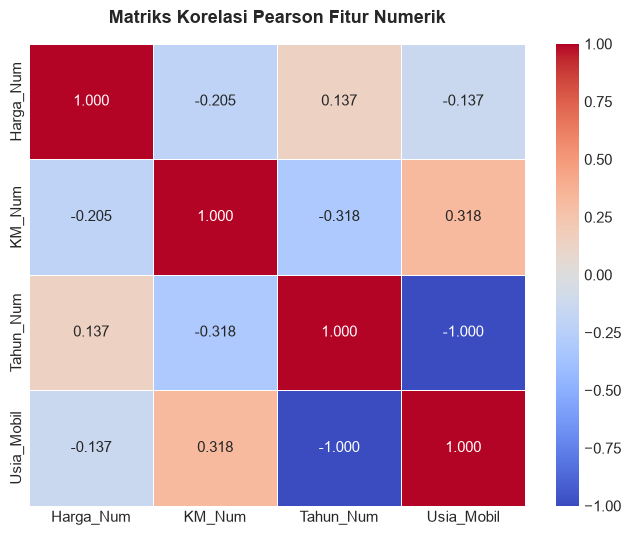

In [12]:
# 1. Matriks Korelasi Pearson
corr_matrix = df_eda[['Harga_Num', 'KM_Num', 'Tahun_Num', 'Usia_Mobil']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Matriks Korelasi Pearson Fitur Numerik', fontsize=13, fontweight='bold', pad=15)
plt.show()


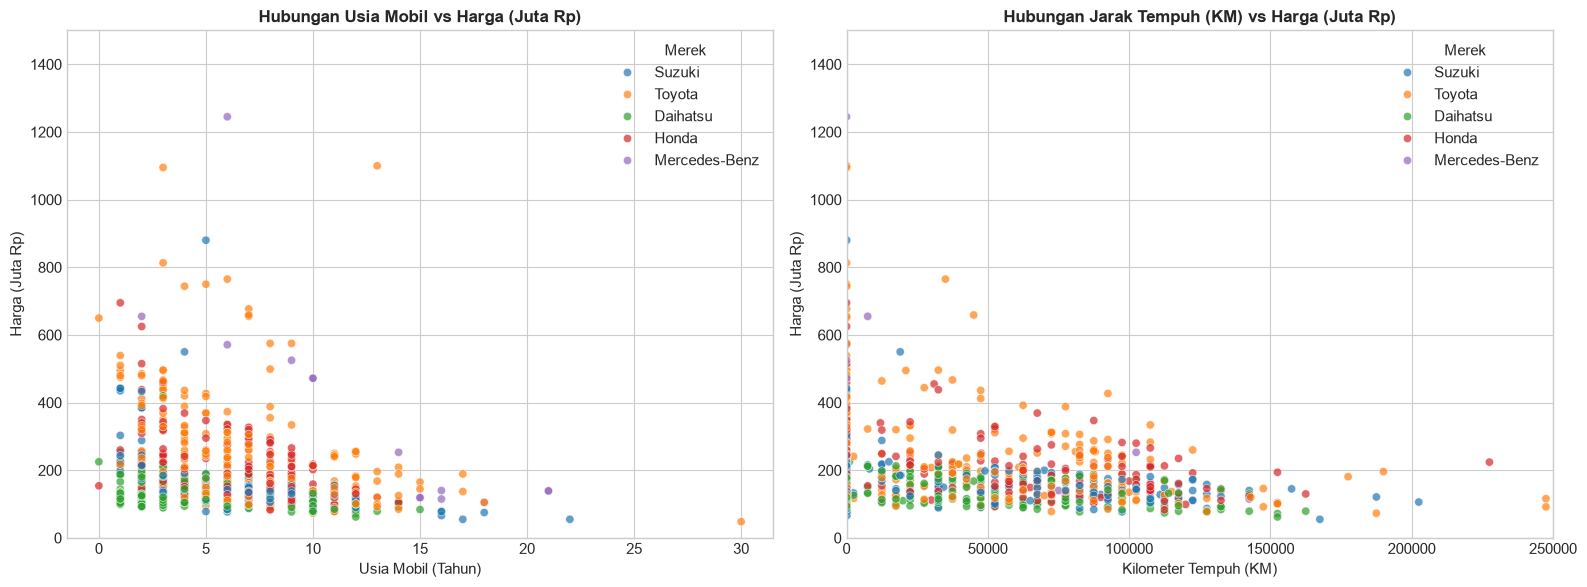

In [13]:
# 2. Scatter Plot: Hubungan Usia & KM terhadap Harga
sample_eda = df_filtered_brands.dropna(subset=['Usia_Mobil', 'Harga_Num', 'KM_Num']).sample(n=1000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Usia Mobil vs Harga
sns.scatterplot(x='Usia_Mobil', y=sample_eda['Harga_Num']/1e6, hue='Merek', data=sample_eda, ax=axes[0], alpha=0.7)
axes[0].set_title('Hubungan Usia Mobil vs Harga (Juta Rp)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Usia Mobil (Tahun)')
axes[0].set_ylabel('Harga (Juta Rp)')
axes[0].set_ylim(0, 1500)

# Kilometer vs Harga
sns.scatterplot(x='KM_Num', y=sample_eda['Harga_Num']/1e6, hue='Merek', data=sample_eda, ax=axes[1], alpha=0.7)
axes[1].set_title('Hubungan Jarak Tempuh (KM) vs Harga (Juta Rp)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Kilometer Tempuh (KM)')
axes[1].set_ylabel('Harga (Juta Rp)')
axes[1].set_xlim(0, 250000)
axes[1].set_ylim(0, 1500)

plt.tight_layout()
plt.show()


### 💡 Interpretasi Hubungan Antar-Variabel:
1. **Tahun Produksi vs Harga ($r = +0.473$):** Memiliki hubungan positif yang kuat. Semakin muda usia mobil (tahun semakin baru), harga jualnya semakin tinggi. Kurva scatter plot menunjukkan pola depresiasi harga yang melengkung turun secara eksponensial pada 5 tahun pertama.
2. **Jarak Tempuh (Kilometer) vs Harga ($r = -0.178$):** Berbanding terbalik (korelasi negatif). Mobil dengan odometer tinggi memiliki harga yang lebih rendah, mencerminkan depresiasi akibat keausan komponen kendaraan.
3. **Merek Sebagai Moderator:** Pada usia yang sama, Mercedes-Benz mempertahankan rentang harga yang jauh lebih tinggi dan menyebar dibandingkan merek Toyota atau Daihatsu.


## 11. Kesimpulan EDA & Rekomendasi Preprocessing (Phase 3)
Berdasarkan seluruh eksplorasi data di atas, berikut adalah kesimpulan komprehensif dan rencana konkret untuk **Phase 3 (Data Preprocessing)**:

| No. | Aspek Temuan EDA | Rencana Tindakan Preprocessing (Phase 3) |
|---|---|---|
| **1** | **Target Harga Missing & Teks** | Parsing teks berformat titik menjadi angka float murni; drop 176 baris (~1%) yang tidak memiliki nilai harga. |
| **2** | **Target Harga Sangat Skewed** | Terapkan transformasi logaritma $\log(1 + 	ext{Harga})$ untuk menstabilkan variansi residual model. |
| **3** | **Artefak Scraping Kolom Merek** | Standarisasi seri mobil Mercedes yang masuk kolom Merek (misal: "C-Class" $\rightarrow$ "Mercedes-Benz"); filter fokus pada 5 merek utama. |
| **4** | **Fitur Kilometer Missing (22%)** | Ekstrak nilai tengah rentang string; lakukan imputasi nilai median berbasis kelompok Model dan Tahun mobil. |
| **5** | **Fitur Kategorikal (Transmisi, Merek, BBM)** | Gunakan *One-Hot Encoding* di dalam scikit-learn `ColumnTransformer` guna mencegah data leakage. |
| **6** | **Penskalaan Fitur untuk Model Linier** | Terapkan `StandardScaler` pada fitur numerik khusus pipeline *Ridge Regression*. |
| **7** | **Strategi Pembagian Data (Validation Scheme)** | Terapkan skema **`GroupShuffleSplit`** (80:20) berdasarkan grup Merek+Model untuk mencegah data leakage antar-iklan mobil sejenis. |
